In [11]:
import subprocess
import sys

# This bypasses the command line path issue completely using a safe execution list
print("Starting safe background installation...")
try:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "pandas", "numpy", "matplotlib"])
    print("\n🚀 Success! All packages installed perfectly.")
    
    # Verify imports inside the same kernel
    import pandas as pd
    import numpy as np
    import matplotlib.pyplot as plt
    print("Verification passed! You are ready to run your Netflix code.")
except Exception as e:
    print(f"\n❌ Installation failed: {e}")


Starting safe background installation...

🚀 Success! All packages installed perfectly.
Verification passed! You are ready to run your Netflix code.


📊 NETFLIX DATASET METRICS & DIAGNOSTICS
🔹 Rows: 8790 | Columns: 10

🔹 Duplicate Rows: 0

🔹 Dataset General Info:
<class 'pandas.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8790 non-null   str  
 1   type          8790 non-null   str  
 2   title         8790 non-null   str  
 3   director      8790 non-null   str  
 4   country       8790 non-null   str  
 5   date_added    8790 non-null   str  
 6   release_year  8790 non-null   int64
 7   rating        8790 non-null   str  
 8   duration      8790 non-null   str  
 9   listed_in     8790 non-null   str  
dtypes: int64(1), str(9)
memory usage: 686.8 KB
None
--------------------------------------------------
🔹 Breakdown of Formatting Issues & Gaps:
Column [show_id]:
  - Leading/Trailing Spaces: 0
  - Unusable/Missing Rows (NaN/Placeholders): 0
Column [type]:
  - Leading/Trailing Spaces: 0
  - Unusabl

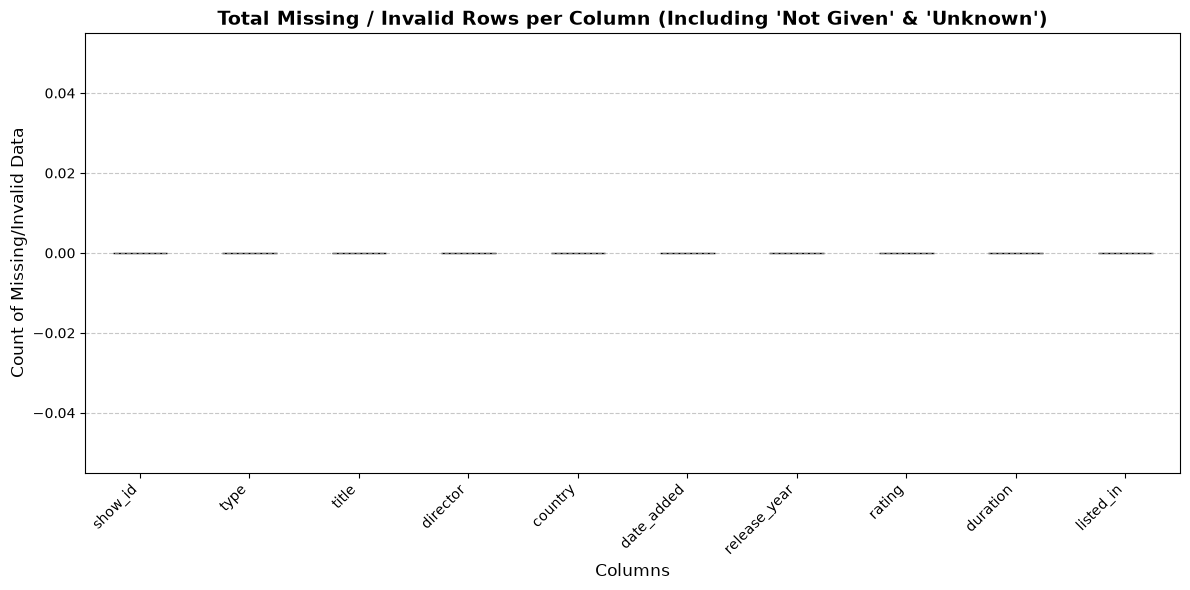

Mean used: 2014.183162684869
Median used: 2017.0
Mode used: United States


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"
...,...,...,...,...,...,...,...,...,...,...
8785,s8797,TV Show,Yunus Emre,NaN,Turkey,1/17/2017,2016,TV-PG,2 Seasons,"International TV Shows, TV Dramas"
8786,s8798,TV Show,Zak Storm,NaN,United States,9/13/2018,2016,TV-Y7,3 Seasons,Kids' TV
8787,s8801,TV Show,Zindagi Gulzar Hai,NaN,Pakistan,12/15/2016,2012,TV-PG,1 Season,"International TV Shows, Romantic TV Shows, TV ..."
8788,s8784,TV Show,Yoko,NaN,Pakistan,6/23/2018,2016,TV-Y,1 Season,Kids' TV


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

file_path = "C:/Users/OM KAPALE/OneDrive/Desktop/Java Training/python/8thday/netflix1.csv"
df = pd.read_csv(file_path)

print("📊 NETFLIX DATASET METRICS & DIAGNOSTICS")


print(f"🔹 Rows: {df.shape[0]} | Columns: {df.shape[1]}\n")
print(f"🔹 Duplicate Rows: {df.duplicated().sum()}\n")

print("🔹 Dataset General Info:")
print(df.info())
print("-" * 50)

print("🔹 Breakdown of Formatting Issues & Gaps:")
space_counts = {}
placeholder_counts = {}

for col in df.columns:
    if df[col].dtype == 'object':
        has_spaces = df[col].astype(str).str.strip() != df[col].astype(str)
        has_spaces = has_spaces & df[col].notnull() & (df[col].astype(str).str.strip() != "")
        space_counts[col] = has_spaces.sum()
        
        is_placeholder = df[col].astype(str).str.strip().isin(["Not Given", "Unknown", ""]) | df[col].isnull()
        placeholder_counts[col] = is_placeholder.sum()
    else:
        space_counts[col] = 0
        placeholder_counts[col] = df[col].isnull().sum()

for col in df.columns:
    print(f"Column [{col}]:")
    print(f"  - Leading/Trailing Spaces: {space_counts[col]}")
    print(f"  - Unusable/Missing Rows (NaN/Placeholders): {placeholder_counts[col]}")

print("="*50)

plt.figure(figsize=(12, 6))
pd.Series(placeholder_counts).plot(kind="bar", color="crimson", edgecolor="black")
plt.title("Total Missing / Invalid Rows per Column (Including 'Not Given' & 'Unknown')", fontsize=14, fontweight="bold")
plt.xlabel("Columns", fontsize=12)
plt.ylabel("Count of Missing/Invalid Data", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()


df = df.drop(index = 26)
df.to_csv("file_path", index=False)

file_path = "C:/Users/OM KAPALE/OneDrive/Desktop/Java Training/python/8thday/netflix1.csv"
df = pd.read_csv(file_path)

df.replace(["Not Given", "Unknown", ""], np.nan, inplace=True)

df["release_year"] = pd.to_numeric(df["release_year"], errors="coerce")

df_mean = df.copy()
mean_value = df_mean["release_year"].mean()
df_mean["release_year"] = df_mean["release_year"].fillna(mean_value)

df_median = df.copy()
median_value = df_median["release_year"].median()
df_median["release_year"] = df_median["release_year"].fillna(median_value)

df_mode = df.copy() 
mode_value = df_mode["country"].mode()[0]
df_mode["country"] = df_mode["country"].fillna(mode_value)

df_label = df.copy()
df_label["director"] = df_label["director"].fillna("Missing Director")

print("Mean used:", mean_value)
print("Median used:", median_value)
print("Mode used:", mode_value)

df


In [23]:
qq = df["release_year"].quantile(0.25)
qqq = df["release_year"].quantile(0.75)
iqr = qqq - qq

low = qq - 1.5 * iqr
high = qqq + 1.5 * iqr

print("Q1, Q3, IQR:", qq, qqq, iqr)
print("Limits:", low, high)


print(df[(df["release_year"] < low) | (df["release_year"] > high)])

Q1, Q3, IQR: 2013.0 2019.0 6.0
Limits: 2004.0 2028.0
     show_id     type                                title          director  \
4         s8    Movie                              Sankofa      Haile Gerima   
29       s25    Movie                                Jeans        S. Shankar   
51       s27    Movie                       Minsara Kanavu       Rajiv Menon   
53       s23    Movie                      Avvai Shanmughi    K.S. Ravikumar   
60       s42    Movie                                 Jaws  Steven Spielberg   
...      ...      ...                                  ...               ...   
8702   s8232    Movie                             The Bund               NaN   
8743   s8524  TV Show    The Super Mario Bros. Super Show!               NaN   
8746   s8542  TV Show  The Twilight Zone (Original Series)               NaN   
8761   s8645  TV Show                           Twin Peaks               NaN   
8765   s8670  TV Show                        V.R. Troopers         

In [29]:
df.loc[df["release_year"] > 10, "release_year"] = np.nan
df["release_year"] = df["release_year"].fillna(df["release_year"].median)
df["country"] = df["country"].fillna("Unknown")

print(df)
print("Missing:", df.isnull().sum().sum())

TypeError: '>' not supported between instances of 'method' and 'int'

In [31]:
print(df["release_year"].clip(50, 90).tolist())

TypeError: '>=' not supported between instances of 'method' and 'int'

In [32]:
import pandas as pd

df = pd.DataFrame({
    'Names': ['  alice smith ', 'BOB JONES  ', ' chaRlie  bRowN ', 'BOB JONES  '],
    'Prices': ['10', '25', 'missing', '25']
})

df['Names'] = df['Names'].str.strip().str.title()

df['Prices'] = pd.to_numeric(df['Prices'], errors='coerce')
df['Prices'] = df['Prices'].fillna(0).astype(int)

duplicate_count = df.duplicated().sum()
df = df.drop_duplicates()

print(f"Duplicates removed: {duplicate_count}")
print(df)


Duplicates removed: 1
            Names  Prices
0     Alice Smith      10
1       Bob Jones      25
2  Charlie  Brown       0
